# Subscription Pricing Decision Under Uncertainty (Monte Carlo Simulation)

**Business question:** "BrewBox", a 20-store coffee chain, is considering a monthly coffee subscription. Should it keep the status quo, launch **Plan A at $14.99/month**, or **Plan B at $19.99/month**? Sign-ups, churn, how often subscribers redeem, and how many paying customers switch to the subscription (cannibalization) are all uncertain.

**Approach:** simulate 1,000 independent 12-month years for each option, then compare expected profit, downside risk (5th percentile), and the probability each plan beats the status quo. Finish with a stress test on the two assumptions management is least sure about: churn and redemption.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
REPS, MONTHS, DAYS_PER_MONTH, STORES = 1000, 12, 30, 20
SETUP_COST, CAC = 40_000, 3.20            # one-time launch cost; acquisition cost per sign-up
PRICE, UNIT_COST = 2.49, 0.62             # per coffee
DEMAND = dict(mean=210, sd=40, lo=120, hi=320)   # daily cups per store without a plan

PLANS = {
    "Plan A ($14.99)": dict(price=14.99, signups=(60, 90, 120), churn=(0.09, 0.13), redeem=(0.35, 0.45), cannibal=(0.09, 0.22, 0.37)),
    "Plan B ($19.99)": dict(price=19.99, signups=(15, 25, 35),  churn=(0.08, 0.16), redeem=(0.30, 0.50), cannibal=(0.10, 0.20, 0.35)),
}

## Model logic
- **Daily baseline demand** per store: normal(210, 40), truncated to 120 to 320 cups.
- **Each month:** a uniform churn rate removes subscribers; each store adds triangular(low, mode, high) sign-ups at $3.20 acquisition cost; subscribers pay the monthly fee.
- **Each day:** a uniform share of subscribers redeems a coffee (we pay the unit cost); a triangular share of those redemptions replaces a cup that would have been bought at full price (cannibalization).
- **Plans carry a $40,000 setup cost.**

In [2]:
def baseline_cups(n_days):
    d = rng.normal(DEMAND["mean"], DEMAND["sd"], size=(REPS, n_days, STORES))
    return np.clip(d, DEMAND["lo"], DEMAND["hi"]).sum(axis=2)          # cups across all stores, per day

def simulate(plan=None, churn_shift=0.0, redeem_shift=0.0):
    days = MONTHS * DAYS_PER_MONTH
    base = baseline_cups(days)
    if plan is None:                                                     # status quo
        return (base * (PRICE - UNIT_COST)).sum(axis=1)

    p = plan
    subs = np.zeros(REPS)
    profit = np.full(REPS, -float(SETUP_COST))
    cannibal = rng.triangular(*p["cannibal"], size=REPS)               # one switching rate per simulated year
    for m in range(MONTHS):
        churn = np.clip(rng.uniform(*p["churn"], size=REPS) + churn_shift, 0, 1)
        subs = subs - np.floor(subs * churn)
        new = np.floor(rng.triangular(*p["signups"], size=(REPS, STORES)).sum(axis=1))
        subs = subs + new
        profit += subs * p["price"] - new * CAC
        sl = slice(m * DAYS_PER_MONTH, (m + 1) * DAYS_PER_MONTH)
        redeem = np.clip(rng.uniform(*p["redeem"], size=(REPS, DAYS_PER_MONTH)) - redeem_shift, 0, 1)
        redemptions = np.floor(subs[:, None] * redeem)
        lost_sales = np.minimum(redemptions * cannibal[:, None], base[:, sl])
        profit += ((base[:, sl] - lost_sales) * (PRICE - UNIT_COST) - redemptions * UNIT_COST).sum(axis=1)
    return profit

def summarize(results):
    base = results["Status quo"]
    rows = {}
    for name, arr in results.items():
        rows[name] = {"Mean profit": arr.mean(), "P5 (downside)": np.percentile(arr, 5),
                      "P95 (upside)": np.percentile(arr, 95), "Std dev": arr.std(),
                      "P(beats status quo)": np.nan if name == "Status quo" else (arr > base).mean()}
    return pd.DataFrame(rows).T

results = {"Status quo": simulate()}
for name, p in PLANS.items():
    results[name] = simulate(p)
table = summarize(results)
fmt = {c: "${:,.0f}".format for c in ["Mean profit", "P5 (downside)", "P95 (upside)", "Std dev"]}
fmt["P(beats status quo)"] = lambda v: "" if pd.isna(v) else f"{v:.0%}"
print(table.to_string(formatters=fmt))
print(f"\nPlan A uplift vs status quo: ${table.loc['Plan A ($14.99)','Mean profit']-table.loc['Status quo','Mean profit']:,.0f}")
print(f"Plan B uplift vs status quo: ${table.loc['Plan B ($19.99)','Mean profit']-table.loc['Status quo','Mean profit']:,.0f}")

                Mean profit P5 (downside) P95 (upside)  Std dev P(beats status quo)
Status quo       $2,829,461    $2,819,270   $2,839,386   $6,242                 NaN
Plan A ($14.99)  $2,964,932    $2,758,163   $3,162,987 $122,621                 85%
Plan B ($19.99)  $2,971,909    $2,917,899   $3,020,730  $31,255                100%

Plan A uplift vs status quo: $135,471
Plan B uplift vs status quo: $142,448


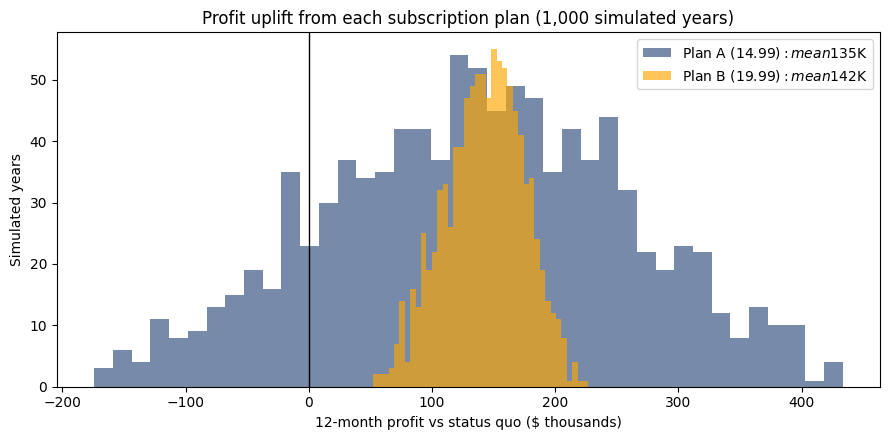

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
uplift = {k: (v - results["Status quo"]) / 1000 for k, v in results.items() if k != "Status quo"}
for (name, arr), color in zip(uplift.items(), ["#2f4b7c", "#ffa600"]):
    ax.hist(arr, bins=40, alpha=0.65, color=color, label=f"{name}: mean ${arr.mean():,.0f}K")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("12-month profit vs status quo ($ thousands)")
ax.set_ylabel("Simulated years")
ax.set_title("Profit uplift from each subscription plan (1,000 simulated years)")
ax.legend()
plt.tight_layout(); plt.savefig("images/profit_uplift.png", dpi=150); plt.show()

## Stress test: what if churn is higher or redemption is lower than expected?

In [4]:
scenarios = {"Base case": {}, "Churn +10 pts": {"churn_shift": 0.10}, "Redemption -10 pts": {"redeem_shift": 0.10}}
rows = []
for scen, kw in scenarios.items():
    sq = simulate()
    for name, p in PLANS.items():
        arr = simulate(p, **kw)
        rows.append({"Scenario": scen, "Plan": name, "Mean uplift": (arr - sq).mean(), "P(beats status quo)": (arr > sq).mean()})
stress = pd.DataFrame(rows).pivot(index="Scenario", columns="Plan")
print(stress.to_string(float_format=lambda v: f"{v:,.2f}"))

                       Mean uplift                 P(beats status quo)                
Plan               Plan A ($14.99) Plan B ($19.99)     Plan A ($14.99) Plan B ($19.99)
Scenario                                                                              
Base case               129,967.59      140,794.71                0.83            1.00
Churn +10 pts            69,676.55       92,344.96                0.76            1.00
Redemption -10 pts      425,101.83      220,357.56                1.00            1.00


## Recommendation

- **Launch Plan B ($19.99).** It adds about **$142K** of profit over 12 months versus the status quo and beats it in **100%** of simulated years. Plan A adds a similar average (about $135K) but beats the status quo in only **85%** of years, with roughly 4x the volatility (std dev $123K vs $31K).
- **Plan B's worst case is still better than doing nothing:** its 5th-percentile profit ($2.92M) sits above the status quo's typical year ($2.83M). Plan A's 5th percentile falls below it.
- **Churn is the key risk.** A 10-point rise in churn cuts Plan A's uplift roughly in half and Plan B's by about a third, so launch with a retention offer and a churn dashboard from month one.
- **Lower redemption helps** (subscribers pay but redeem less), so redemption is a lever, not a threat.

**Skills shown:** Monte Carlo simulation, probability distributions (triangular, uniform, truncated normal), risk metrics (P5/P95, probability of beating a baseline), sensitivity analysis, vectorized NumPy.